<a href="https://colab.research.google.com/github/asiyyajm/AJ-CSC_FinalProject/blob/main/AJ_CSC_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Predicting Parkinson’s Motor Symptom Severity from Voice Measurements**
## CSC321 Final Project
### Asiya Jaffer

*Abstract:* This project investigates how machine learning can be used to predict the severity of Parkinson's disease motor symptoms using voice measurements. Using the Parkinson's Telemonitoring dataset from the UCI Machine Learning Repository, which contains 5,875 recordings from 42 patients, we will examine how different voice features contribute to predicting motor UPDRS scores. We will compare several regression algorithms, identify the most important voice measurements, and investigate how removing or combining features affects prediction accuracy. We will also examine whether age, sex, and test time improve predictions. By analyzing these results, we aim to better understand which features are most useful for predicting Parkinson's motor symptom severity and how feature selection influences machine learning performance.

###Introduction
The goal of this project is to estimate the severity of Parkinson’s motor symptoms from measurements taken from voice recordings. The target is the motor score from the Unified Parkinson’s Disease Rating Scale (UPDRS). I will treat the task as a regression problem because this score is numerical. I will measure prediction error using root mean squared error (RMSE), reported in motor UPDRS points.
The dataset includes multiple recordings per patient, so I will keep each patient’s recordings together when splitting the data. This lets us test how well the models predict scores for patients that have not been seen yet. I will also investigate whether a smaller set of voice measurements can perform as well as the full set and whether patient characteristics or the timing of a recording improve predictions.


**Questions:**


1.   How accurately can voice measurements predict the severity of Parkinson's symptoms?
2.   Which voice measurements are the strongest predictors of Parkinson's symptom severity?


1.   How does selecting different groups of voice measurements affect the accuracy of predicting Parkinson's severity?
2.   How do age and gender compare to voice measurements in predicting Parkinson's symptoms severity?










###Motivation
Assessing Parkinson’s motor symptoms with the Unified Parkinson’s Disease Rating Scale (UPDRS) requires an examination by trained clinical staff. On the other hand, in order to gather information between visits, voice recordings can be collected at home. Through the Parkinson’s Telemonitoring dataset, measurements from these recordings are used to estimate UPDRS scores. This work motivates one of my questions: how well can voice measurements predict motor UPDRS scores for patients whose recordings were held out of training?

A 2020 study using a deep neural network on the same dataset reported a test RMSE of 1.42 motor UPDRS points. A 2026 study using an Extra Trees regressor and all 16 voice measurements reported a mean absolute error (MAE) of 7.21 motor UPDRS points when it held out one patient at a time. The second study also reported higher error under patient-level evaluation than under recording-level evaluation. The two error values use different metrics and evaluation setups, so a direct numerical comparison would be misleading.

In my project, I'll compare regression models with a ZeroR baseline that predicts the mean motor UPDRS score from the training data. On the same held-out patients, I'll examine how prediction error changes when we use individual voice measurements, compare jitter and shimmer feature groups with the full voice feature set and add age, sex, and test time. This lets us assess how much each set of inputs helps predict motor UPDRS scores for new patients.


###Data
I am going to be using the Parkinson’s Telemonitoring dataset from the UCI Machine Learning Repository. The CSV contains 5,875 rows and 22 columns. Each row contains measurements from one voice recording. The recordings were collected at home from 42 people with early-stage Parkinson’s disease during a six-month study; each participant contributed multiple recordings.

The file includes a participant ID, age, sex, time in days relative to recruitment, two UPDRS scores and 16 numerical voice measurements. These include five jitter measures that describe variation in voice frequency, six shimmer measures that describe variation in amplitude, and five other measures that capture properties such as the balance between noise and tone in the voice. Participant ages range from 36 to 85 years, and the dataset codes sex as 0 for male and 1 for female. My prediction target is motor_UPDRS, which ranges from 5.04 to 39.51 points. I will use subject# to keep each participant’s recordings together when splitting the data and exclude both subject# and total_UPDRS from the predictors.

After reviewing CSV, I found no missing values or exact duplicate rows. Additionally, the amount of recording noise is unknown at this stage.


###Experiments

In [36]:
import pandas as pd
from google.colab import drive

drive.mount("/content/drive")

parkinsons = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks CSC321/park/parkinsons_updrs.csv"
)


print("Rows and columns:", parkinsons.shape)

parkinsons[["age", "test_time", "motor_UPDRS"]].describe()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Rows and columns: (5875, 22)


,age,test_time,motor_UPDRS
count,5875.000000,5875.000000,5875.000000
mean,64.804936,92.863722,21.296229
std,8.821524,53.445602,8.129282
min,36.000000,-4.262500,5.037700
25%,58.000000,46.847500,15.000000
50%,65.000000,91.523000,20.871000
75%,72.000000,138.445000,27.596500
max,85.000000,215.490000,39.511000


I first tested whether the 16 voice measurements could improve predictions of motor UPDRS scores. I used ZeroR as a baseline because it predicts the average motor UPDRS score from the training data. I then used multiple linear regression to see whether combining the voice measurements could reduce prediction error. Both models used the same 10 folds, with all recordings from each participant kept together. I calculated the RMSE on each test fold and averaged the 10 scores.

In [37]:
from sklearn.model_selection import KFold

participant_ids = []

for participant_id in parkinsons["subject#"]:
    if participant_id not in participant_ids:
        participant_ids.append(participant_id)

folds = KFold(n_splits=10, shuffle=True, random_state=42)
participant_splits = list(folds.split(participant_ids))

print("Number of participants:", len(participant_ids))
print("Number of folds:", len(participant_splits))

Number of participants: 42
Number of folds: 10


In [38]:
from math import sqrt
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import MinMaxScaler

knn_scores = []

data = parkinsons.values
X = data[:, 6:]  # The 16 vm
y = data[:, 4]   # motor_UPDRS

zeroR_scores = []
linear_scores = []

for train_index, test_index in participant_splits:
    test_ids = []
    for i in test_index:
        test_ids.append(participant_ids[i])

    train_rows = []
    test_rows = []

    for i in range(len(data)):
        if data[i, 0] in test_ids:
            test_rows.append(i)
        else:
            train_rows.append(i)

    X_train = X[train_rows]
    X_test = X[test_rows]
    y_train = y[train_rows]
    y_test = y[test_rows]

    zr = DummyRegressor(strategy="mean")
    zr.fit(X_train, y_train)
    zr_predY = zr.predict(X_test)
    zeroR_scores.append(sqrt(mean_squared_error(y_test, zr_predY)))

    lr = LinearRegression()
    lr.fit(X_train, y_train)
    lr_predY = lr.predict(X_test)
    linear_scores.append(sqrt(mean_squared_error(y_test, lr_predY)))

    scaler = MinMaxScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    knn = KNeighborsRegressor(n_neighbors=1)
    knn.fit(X_train_scaled, y_train)
    knn_predY = knn.predict(X_test_scaled)
    knn_scores.append(sqrt(mean_squared_error(y_test, knn_predY)))

print("Average ZeroR RMSE:", round(sum(zeroR_scores) / len(zeroR_scores), 2))
print("Average linear regression RMSE:", round(sum(linear_scores) / len(linear_scores), 2))
print("Average 1-NN RMSE:", round(sum(knn_scores) / len(knn_scores), 2))

Average ZeroR RMSE: 8.16
Average linear regression RMSE: 8.3
Average 1-NN RMSE: 11.26


In [39]:
fold_results = []
linear_wins = 0

for i in range(len(zeroR_scores)):
    fold_results.append([
        i + 1,
        round(zeroR_scores[i], 2),
        round(linear_scores[i], 2)
    ])

    if linear_scores[i] < zeroR_scores[i]:
        linear_wins += 1

print("Linear regression beat ZeroR in", linear_wins,
      "out of", len(zeroR_scores), "folds.")

pd.DataFrame(
    fold_results,
    columns=["Fold", "ZeroR RMSE", "Linear Regression RMSE"]
)

Linear regression beat ZeroR in 4 out of 10 folds.


,Fold,ZeroR RMSE,Linear Regression RMSE
0,1,8.18,8.02
1,2,6.92,7.80
2,3,10.10,10.39
3,4,9.24,10.44
4,5,8.37,9.07
5,6,10.33,9.79
6,7,6.85,5.44
7,8,9.09,10.06
8,9,6.40,5.89
9,10,6.13,6.15


Linear regression had a lower RMSE than ZeroR in 4 of the 10 folds. Its biggest improvement was in fold 7, where RMSE dropped from 6.85 to 5.44, but ZeroR performed better overall.

ZeroR had an average RMSE of 8.16 motor UPDRS points, while multiple linear regression had an average RMSE of 8.3. The linear model’s error was about 0.14 points higher. In this experiment, using all 16 voice measurements together did not improve predictions for held-out participants. Since the average errors were close, I also wanted to see how the two models compared in each fold.

Using the same participant folds, I found that increasing the number of neighbors from 1 to 15 reduced the average RMSE from 11.26 to 8.78. Averaging more neighbors improved the KNN predictions, but ZeroR still had the lowest error at 8.16.

###Jitter VS Shimmer
After testing models with all 16 voice measurements, I wanted to see whether a smaller group of features could predict motor UPDRS scores just as well. I compared five jitter measurements, which describe changes in voice frequency, with six shimmer measurements, which describe changes in voice amplitude. I used linear regression and the same 10 participant folds for both groups so that the only change was which features the model received.&#x20;


In [40]:
jitter_scores = []
shimmer_scores = []

for train_index, test_index in participant_splits:
    test_ids = []
    for i in test_index:
        test_ids.append(participant_ids[i])

    train_rows = []
    test_rows = []
    for i in range(len(data)):
        if data[i, 0] in test_ids:
            test_rows.append(i)
        else:
            train_rows.append(i)

    X_train = X[train_rows]
    X_test = X[test_rows]
    y_train = y[train_rows]
    y_test = y[test_rows]

    lr_jitter = LinearRegression()
    lr_jitter.fit(X_train[:, :5], y_train)
    jitter_predY = lr_jitter.predict(X_test[:, :5])
    jitter_scores.append(sqrt(mean_squared_error(y_test, jitter_predY)))

    lr_shimmer = LinearRegression()
    lr_shimmer.fit(X_train[:, 5:11], y_train)
    shimmer_predY = lr_shimmer.predict(X_test[:, 5:11])
    shimmer_scores.append(sqrt(mean_squared_error(y_test, shimmer_predY)))

print("Average jitter RMSE:", round(sum(jitter_scores) / len(jitter_scores), 2))
print("Average shimmer RMSE:", round(sum(shimmer_scores) / len(shimmer_scores), 2))

Average jitter RMSE: 8.29
Average shimmer RMSE: 8.14


The shimmer model had an average RMSE of 8.14, compared with 8.29 for the jitter model and 8.3 for the model using all 16 voice measurements. Shimmer gave the lowest error in this experiment, but its advantage over ZeroR (8.16) was only about 0.02 motor UPDRS points. On these folds, using shimmer alone works slightly better than using all 16 voice measurements.

Since the shimmer measurements gave the lowest error in the group comparison, I wanted to see whether a single voice measurement could perform just as well on its own. I fit a separate simple linear regression model for each voice measurement and compared their average RMSE across the same 10 participant folds.

In [41]:
voice_names = parkinsons.columns[6:]
feature_scores = []

for j in range(len(voice_names)):
    feature_scores.append([])

for train_index, test_index in participant_splits:
    test_ids = []
    for i in test_index:
        test_ids.append(participant_ids[i])

    train_rows = []
    test_rows = []
    for i in range(len(data)):
        if data[i, 0] in test_ids:
            test_rows.append(i)
        else:
            train_rows.append(i)

    X_train = X[train_rows]
    X_test = X[test_rows]
    y_train = y[train_rows]
    y_test = y[test_rows]

    for j in range(len(voice_names)):
        lr = LinearRegression()
        lr.fit(X_train[:, j:j+1], y_train)
        lr_predY = lr.predict(X_test[:, j:j+1])
        feature_scores[j].append(sqrt(mean_squared_error(y_test, lr_predY)))

feature_results = []
for j in range(len(voice_names)):
    average_rmse = sum(feature_scores[j]) / len(feature_scores[j])
    feature_results.append([voice_names[j], round(average_rmse, 2)])

pd.DataFrame(feature_results, columns=["Voice measurement", "Average RMSE"])

,Voice measurement,Average RMSE
0,Jitter(%),8.16
1,Jitter(Abs),8.18
2,Jitter:RAP,8.16
3,Jitter:PPQ5,8.17
4,Jitter:DDP,8.16
5,Shimmer,8.14
6,Shimmer(dB),8.13
7,Shimmer:APQ3,8.15
8,Shimmer:APQ5,8.15
9,Shimmer:APQ11,8.12


HNR and Shimmer: APQ11 had the lowest average RMSE of the individual voice measurements, both 8.12. Each performed slightly better than the shimmer only model: 8.14 and zeroR: 8.16. The improvement over zeroR was only about 0.04 motor UPDRS points on these folds.

### Age, sex and test time
After comparing the voice measurements, I wanted to see whether participant information could improve motor UPDRS predictions. I started with the model that used all 16 voice measurements, then added age, sex and test time. I kept the same linear regression method and participant folds so I could compare how each addition affected the average RMSE.

In [42]:
voice_columns = list(range(6, 22))
X_age_sex = data[:, [1, 2] + voice_columns]
X_age_sex_time = data[:, [1, 2, 3] + voice_columns]

age_sex_scores = []
age_sex_time_scores = []

for train_index, test_index in participant_splits:
    test_ids = []
    for i in test_index:
        test_ids.append(participant_ids[i])

    train_rows = []
    test_rows = []
    for i in range(len(data)):
        if data[i, 0] in test_ids:
            test_rows.append(i)
        else:
            train_rows.append(i)

    y_train = y[train_rows]
    y_test = y[test_rows]

    lr_age_sex = LinearRegression()
    lr_age_sex.fit(X_age_sex[train_rows], y_train)
    age_sex_pred = lr_age_sex.predict(X_age_sex[test_rows])
    age_sex_scores.append(sqrt(mean_squared_error(y_test, age_sex_pred)))

    lr_age_sex_time = LinearRegression()
    lr_age_sex_time.fit(X_age_sex_time[train_rows], y_train)
    age_sex_time_pred = lr_age_sex_time.predict(X_age_sex_time[test_rows])
    age_sex_time_scores.append(sqrt(mean_squared_error(y_test, age_sex_time_pred)))

print("Voice only:", round(sum(linear_scores) / len(linear_scores), 2))
print("Voice + age and sex:", round(sum(age_sex_scores) / len(age_sex_scores), 3))
print("Voice + age, sex, and test time:",
      round(sum(age_sex_time_scores) / len(age_sex_time_scores), 3))
#I think keeping it as 3 decomal places helps you see the variation only in this case

Voice only: 8.3
Voice + age and sex: 8.522
Voice + age, sex, and test time: 8.518


Adding age and sex increased the average RMSE from 8.3 to 8.52. Adding test time lowered it slightly to 8.518, a difference of only 0.004 points. On the same 10 participant folds, the voice-only model had the lowest prediction error of the three.




---







##Visualization

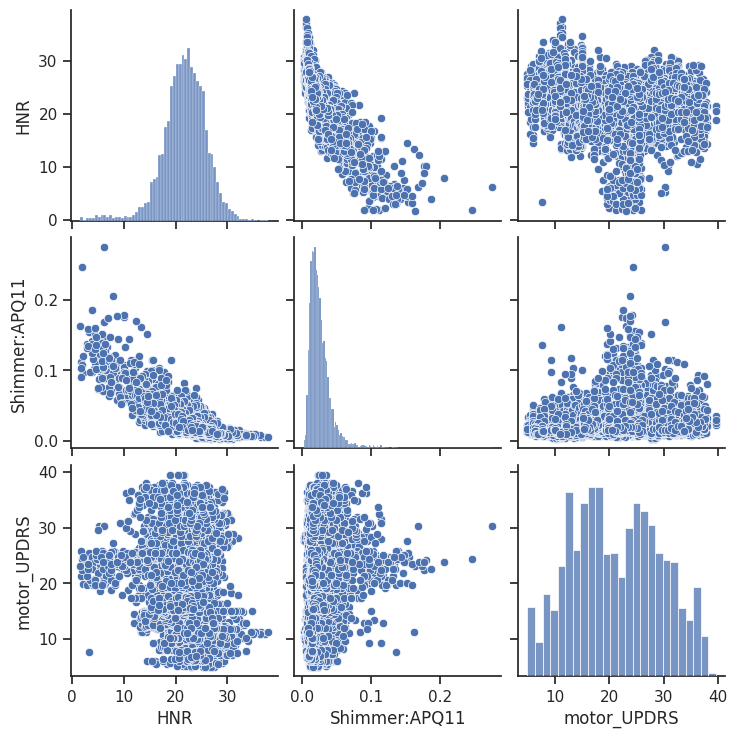

In [43]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style="ticks")

voice_plot = parkinsons[["HNR", "Shimmer:APQ11", "motor_UPDRS"]]
sns.pairplot(voice_plot)
plt.show()


I used a Seaborn pairplot to see how HNR and Shimmer:APQ11, the two voice measurements with the lowest individual prediction errors, relate to motor UPDRS. Each point represents one recording. The two voice measurements tend to move in opposite directions, but neither of them shows a clear linear relationship with motor UPDRS.

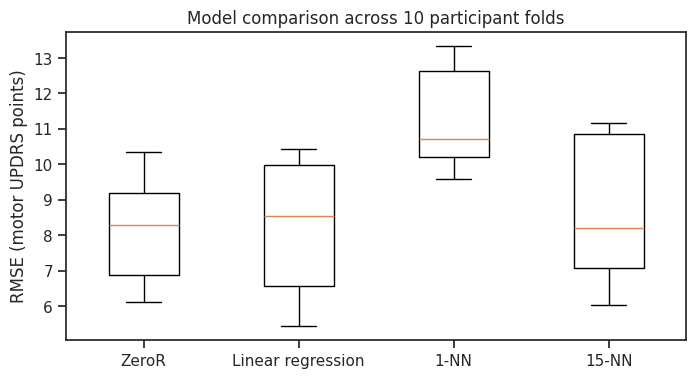

In [44]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import MinMaxScaler

knn_1_scores = []
knn_15_scores = []

for train_index, test_index in participant_splits:
    test_ids = []
    for i in test_index:
        test_ids.append(participant_ids[i])

    train_rows = []
    test_rows = []
    for i in range(len(data)):
        if data[i, 0] in test_ids:
            test_rows.append(i)
        else:
            train_rows.append(i)

    y_train = y[train_rows]
    y_test = y[test_rows]

    scaler = MinMaxScaler()
    X_train_scaled = scaler.fit_transform(X[train_rows])
    X_test_scaled = scaler.transform(X[test_rows])

    knn_1 = KNeighborsRegressor(n_neighbors=1)
    knn_1.fit(X_train_scaled, y_train)
    pred_1 = knn_1.predict(X_test_scaled)
    knn_1_scores.append(sqrt(mean_squared_error(y_test, pred_1)))

    knn_15 = KNeighborsRegressor(n_neighbors=15)
    knn_15.fit(X_train_scaled, y_train)
    pred_15 = knn_15.predict(X_test_scaled)
    knn_15_scores.append(sqrt(mean_squared_error(y_test, pred_15)))

results = [zeroR_scores, linear_scores, knn_1_scores, knn_15_scores]
model_names = ["ZeroR", "Linear regression", "1-NN", "15-NN"]

fig = plt.figure(figsize=(8, 4))
ax = fig.add_subplot(111)
plt.boxplot(results)
ax.set_xticklabels(model_names)
plt.ylabel("RMSE (motor UPDRS points)")
plt.title("Model comparison across 10 participant folds")
plt.show()

I used a boxplot to compare how the RMSE for ZeroR, linear regression, 1-NN, and 15-NN varied across the same 10 participant folds. The orange line in each box shows the median RMSE, and lower values indicate better predictions. The 1-NN model had the highest median error, while 15-NN brought the median much closer to the ZeroR baseline.

### Results

| Model | Features | Mean RMSE |
|---|---|---:|
| ZeroR | None | 8.16 |
| Multiple linear regression | All 16 voice measurements | 8.30 |
| 1-NN | All 16 voice measurements | 11.26 |
| 15-NN | All 16 voice measurements | 8.78 |
| Multiple linear regression | Jitter only | 8.29 |
| Multiple linear regression | Shimmer only | 8.14 |
| Simple linear regression | HNR only | **8.12** |
| Simple linear regression | Shimmer:APQ11 only | **8.12** |
| Multiple linear regression | All voice measurements + age and sex | 8.52 |
| Multiple linear regression | All voice measurements + age, sex, and test time | 8.52 |



This project examined how accurately voice measurements could predict motor UPDRS scores. I expected that using all 16 voice measurements would improve predictions, but multiple linear regression had a mean RMSE of 8.30 motor UPDRS points across the 10 participant folds, compared with 8.16 for ZeroR. Additionally, increasing the number of neighbors from one to fifteen reduced the KNN error from 11.26 to 8.78. This suggests that averaging several nearby recordings made predictions less sensitive to any single match, although the average error remained above the baseline.

HNR and Shimmer: APQ11 were the strongest individual predictors among the 16 measurements tested, with mean RMSE values that both rounded to 8.12. Among the feature groups, shimmer alone produced a lower error: 8.14 than jitter alone: 8.29 or all 16 measurements together: 8.30. These results suggest that a smaller set of voice measurements can perform as well as the full set on these folds. The pairplot offers one possible explanation for the little improvement we were able to see. Recordings with similar HNR or Shimmer: APQ11 values often had quite different motor UPDRS scores, making it difficult to estimate symptom severity from either measurement alone.

Adding age and sex to the full set of voice measurements increased the mean RMSE from 8.304 to 8.522. Adding test time reduced it slightly to 8.518. The voice-only model therefore performed best among these three versions. This comparison shows how age and sex affected predictions when added to the voice model.&#x20;

When looking at similar studies done, the deep learning study reported a motor UPDRS RMSE of 1.42, which is much lower than the best mean RMSE of 8.12 in this project. The studies used different evaluation setups, so we cannot directly compare. Moreover, the Extra Trees study used a more similar approach by holding out entire participants. Still, it reported a mean absolute error of 7.21 and held out one participant at a time. A direct comparison would require us to use the same participant splits and error metric.&#x20;


###Conclusion
I started this project to see whether voice recordings could help predict how severe someone’s Parkinson’s movement symptoms were. The best voice based predictions were only slightly better than using the zeroR symptom score. Furthermore, of the 16 voice measurements I tested one at a time, HNR and Shimmer: APQ11 gave the best results. Using just the shimmer measurements also worked a little better than using just the jitter measurements or all 16 voice measurements together.

As for how age and gender compare to voice measurements in predicting Parkinson's symptom severity, when adding age and sex to the voice measurements, the predictions got worse. Adding the time of the test made almost no difference.

In conclusion, voice measurements predict the severity of Parkinson's symptoms only slightly better than simply predicting the average symptom score.


###References
Archive.Ics.Uci.Edu. n.d. “UCI Machine Learning Repository.” Accessed November 21, 2026. https://archive.ics.uci.edu/dataset/189/parkinsons+telemonitoring.

Essam, Mahmoud, Mazen Balat, Ahmed B Zaky, Mervat Samy, and Ahmed M Anter. 2026. “Adaptive Regression Model for Parkinson’s Disease Diagnosis From Speech Signals Using Box-Cox-Based Clustering and Extremely Randomization.” Scientific Reports (England) 16 (1): 14044. PubMed Central. https://doi.org/10.1038/s41598-026-49065-2.

Simon, ~. 2019. “We Need to Talk About the UPDRS.” The Science of Parkinson’s, March 6. https://scienceofparkinsons.com/2019/03/06/updrs/.

Suppa, Antonio, Giovanni Costantini, Francesco Asci, et al. 2022. “Voice in Parkinson’s Disease: A Machine Learning Study.” Frontiers in Neurology 13 (February): 831428. https://doi.org/10.3389/fneur.2022.831428.

Tsanas, A., M. A. Little, P. E. McSharry, and L. O. Ramig. 2010. “Accurate Telemonitoring of Parkinson’s Disease Progression by Noninvasive Speech Tests.” IEEE Transactions on Biomedical Engineering 57 (4): 884–93. https://doi.org/10.1109/tbme.2009.2036000.

Shahid, Afzal Hussain, and Maheshwari Prasad Singh. 2020. “A Deep Learning Approach for Prediction of Parkinson’s Disease Progression.” Biomedical Engineering Letters (Germany) 10 (2): 227–39. PubMed Central. https://doi.org/10.1007/s13534-020-00156-7.